# Cassava Leaf Disease Classification
Final project, AI Study Jams (Kaggle dataset option).

**Goal**: classify a photo of a cassava leaf into 5 categories (4 diseases + healthy).

**Before running**: in the notebook settings, enable the GPU (T4) and Internet (needed to download the ImageNet weights). Add the data with *Add Input*: the competition *Cassava Leaf Disease Classification*.

## 1. Imports and configuration

In [ ]:
import os, json, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Find train.csv automatically, whether the data comes from the competition or a dataset
csv_paths = glob.glob("/kaggle/input/**/train.csv", recursive=True)
print("train.csv found:", csv_paths)
assert csv_paths, "train.csv not found: check the contents of /kaggle/input (Add Input)"
DATA_DIR = os.path.dirname(csv_paths[0])
IMG_DIR = os.path.join(DATA_DIR, "train_images")
assert os.path.isdir(IMG_DIR), f"train_images folder not found in {DATA_DIR}: {os.listdir(DATA_DIR)}"
IMG_SIZE = 224
BATCH = 32
SAMPLE = None   # None = all images.

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

train.csv found: ['/kaggle/input/competitions/cassava-leaf-disease-classification/train.csv']
TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Loading and exploring the data
The competition test set is hidden (almost nothing is provided in the files). We therefore split `train.csv` ourselves into train / validation / test.

Number of images: 21397
label
Cassava Mosaic Disease (CMD)           13158
Healthy                                 2577
Cassava Green Mottle (CGM)              2386
Cassava Brown Streak Disease (CBSD)     2189
Cassava Bacterial Blight (CBB)          1087
Name: count, dtype: int64


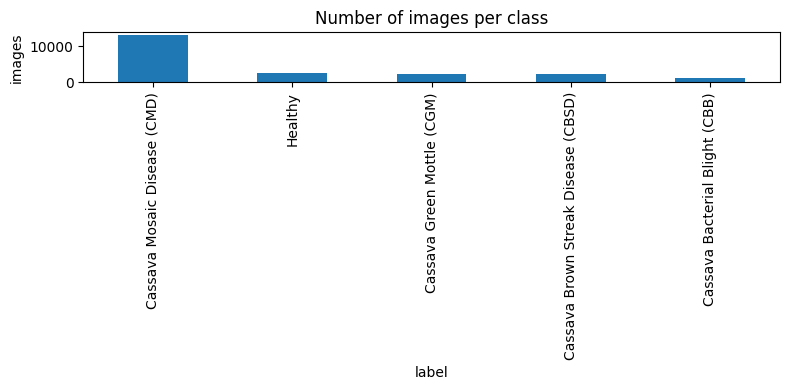

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
json_path = os.path.join(DATA_DIR, "label_num_to_disease_map.json")
if os.path.exists(json_path):
    with open(json_path) as f:
        label_map = {int(k): v for k, v in json.load(f).items()}
else:  # file missing in some datasets: standard competition mapping
    label_map = {0: "Cassava Bacterial Blight (CBB)", 1: "Cassava Brown Streak Disease (CBSD)",
                 2: "Cassava Green Mottle (CGM)", 3: "Cassava Mosaic Disease (CMD)", 4: "Healthy"}
class_names = [label_map[i] for i in range(len(label_map))]
df["path"] = IMG_DIR + "/" + df["image_id"]

print("Number of images:", len(df))
counts = df["label"].map(label_map).value_counts()
print(counts)

counts.plot(kind="bar", figsize=(8, 4), title="Number of images per class")
plt.ylabel("images"); plt.tight_layout(); plt.show()

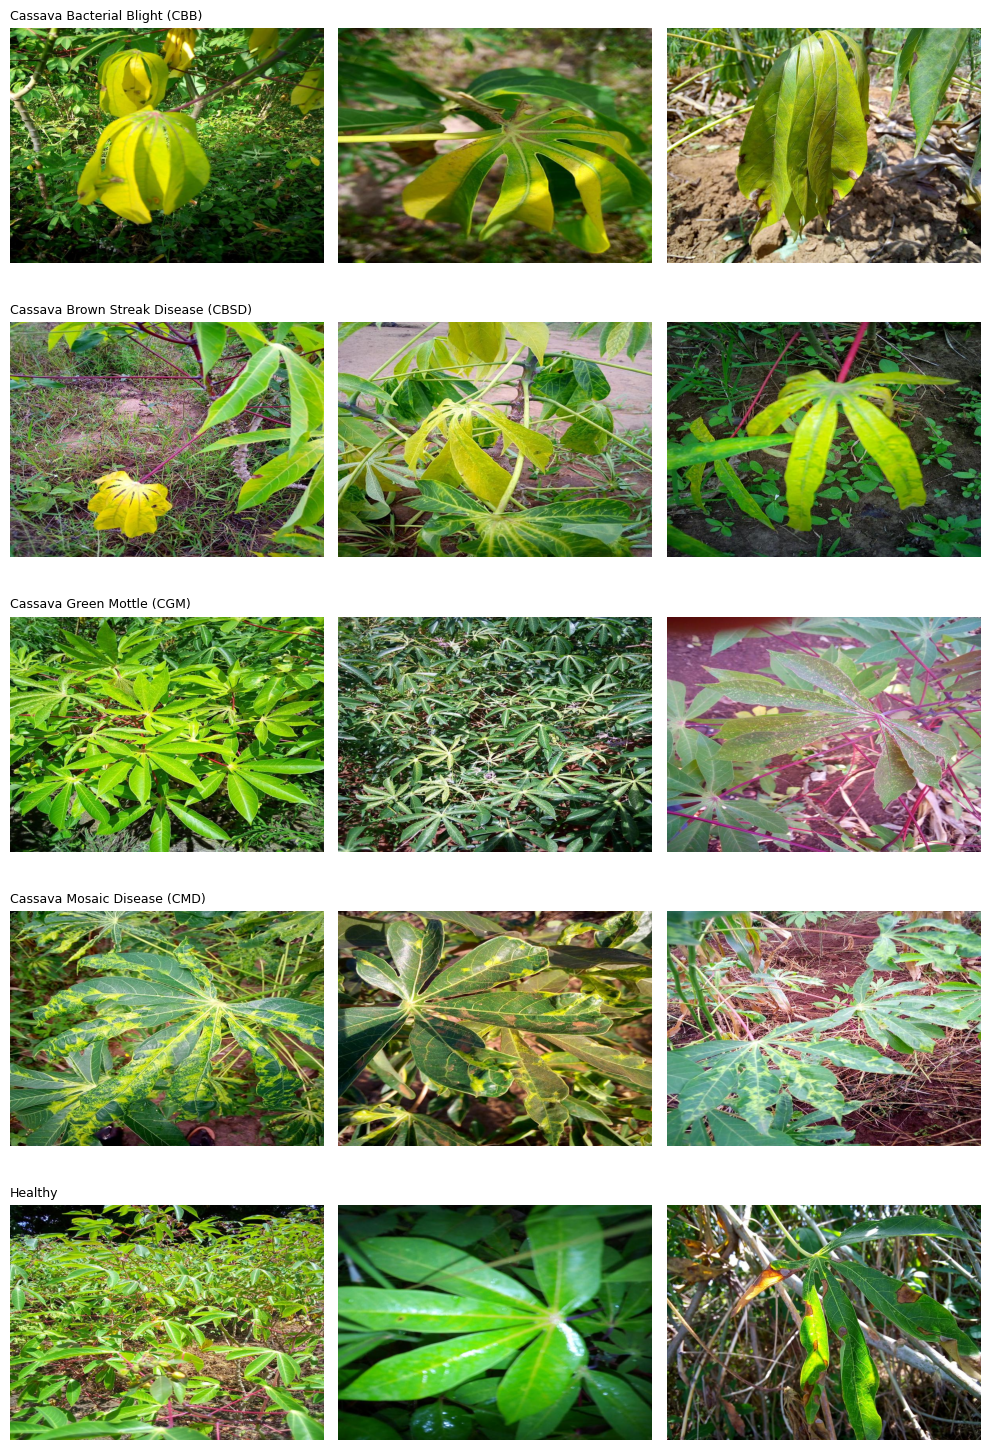

In [3]:
# A few examples per class
fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 3 * len(class_names)))
for i, name in enumerate(class_names):
    sample = df[df["label"] == i].sample(3, random_state=SEED)
    for j, p in enumerate(sample["path"]):
        axes[i, j].imshow(plt.imread(p)); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 3. Train / validation / test split (stratified)

In [4]:
if SAMPLE:
    df = df.sample(SAMPLE, random_state=SEED).reset_index(drop=True)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

14977 3210 3210


## 4. Data pipeline and augmentation

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1),
])

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

# Class weights to compensate for the class imbalance
w = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=train_df["label"].values)
class_weight = dict(enumerate(w))
print(class_weight)

I0000 00:00:1794114257.997750      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794114258.001588      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


{0: np.float64(3.936136662286465), 1: np.float64(1.9552219321148825), 2: np.float64(1.7936526946107785), 3: np.float64(0.3252334419109663), 4: np.float64(1.660421286031042)}


## 5. Model: transfer learning (MobileNetV2)
Step 1: train only the classification head. Step 2: unfreeze the last layers (fine-tuning).

In [6]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=10,
               class_weight=class_weight, callbacks=callbacks)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


2026-11-08 05:04:39.247623: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-08 05:04:39.386198: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794114281.656450     140 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.4079 - loss: 1.5390

2026-11-08 05:06:36.694832: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-08 05:06:36.828202: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.4081 - loss: 1.5387

2026-11-08 05:07:02.007072: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-08 05:07:02.143446: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


469/469 ━━━━━━━━━━━━━━━━━━━━ 163s 304ms/step - accuracy: 0.4773 - loss: 1.3922 - val_accuracy: 0.4333 - val_loss: 1.4007
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 97s 206ms/step - accuracy: 0.5558 - loss: 1.2165 - val_accuracy: 0.5567 - val_loss: 1.1088
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 95s 202ms/step - accuracy: 0.5824 - loss: 1.1588 - val_accuracy: 0.3773 - val_loss: 1.5882
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 96s 204ms/step - accuracy: 0.5862 - loss: 1.1510 - val_accuracy: 0.5302 - val_loss: 1.1796
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 96s 204ms/step - accuracy: 0.5855 - loss: 1.1530 - val_accuracy: 0.5178 - val_loss: 1.2017


In [7]:
# Fine-tuning: unfreeze the last 30 layers with a small learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=25,
               class_weight=class_weight, callbacks=callbacks)

Epoch 1/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 126s 232ms/step - accuracy: 0.4709 - loss: 1.3014 - val_accuracy: 0.6287 - val_loss: 0.9650
Epoch 2/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 119s 202ms/step - accuracy: 0.5736 - loss: 1.1628 - val_accuracy: 0.6769 - val_loss: 0.8734
Epoch 3/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 97s 205ms/step - accuracy: 0.5974 - loss: 1.0988 - val_accuracy: 0.6601 - val_loss: 0.9066
Epoch 4/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 97s 205ms/step - accuracy: 0.6101 - loss: 1.0708 - val_accuracy: 0.6380 - val_loss: 0.9661
Epoch 5/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 96s 204ms/step - accuracy: 0.6198 - loss: 1.0525 - val_accuracy: 0.6009 - val_loss: 1.0450


In [8]:
from sklearn.metrics import f1_score
val_pred = np.argmax(model.predict(val_ds), axis=1)
print("Validation accuracy:", (val_pred == val_df["label"].values).mean())
print("Validation macro F1:", f1_score(val_df["label"].values, val_pred, average="macro"))

101/101 ━━━━━━━━━━━━━━━━━━━━ 14s 93ms/step
Validation accuracy: 0.6769470404984423
Validation macro F1: 0.5441733396731253


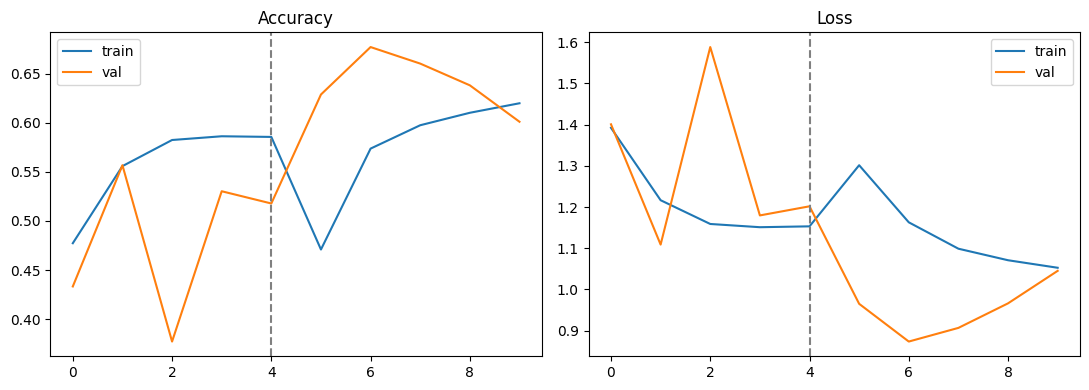

In [9]:
# Learning curves
acc = h1.history["accuracy"] + h2.history["accuracy"]
val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
val_loss = h1.history["val_loss"] + h2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val"); ax[1].set_title("Loss"); ax[1].legend()
for a in ax: a.axvline(len(h1.history["loss"]) - 1, ls="--", c="gray")
plt.tight_layout(); plt.show()

## 6. Evaluation on the test set (used only once)

101/101 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step
                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.435     0.534     0.479       163
Cassava Brown Streak Disease (CBSD)      0.416     0.632     0.502       329
         Cassava Green Mottle (CGM)      0.418     0.483     0.448       358
       Cassava Mosaic Disease (CMD)      0.906     0.754     0.823      1974
                            Healthy      0.477     0.560     0.515       386

                           accuracy                          0.677      3210
                          macro avg      0.530     0.593     0.553      3210
                       weighted avg      0.726     0.677     0.694      3210



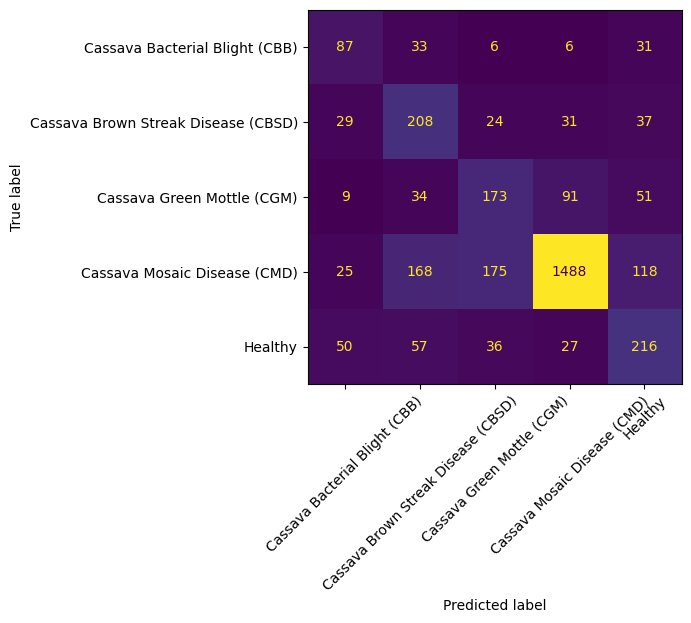

In [10]:
y_true = test_df["label"].values
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

Errors: 1038 out of 3210


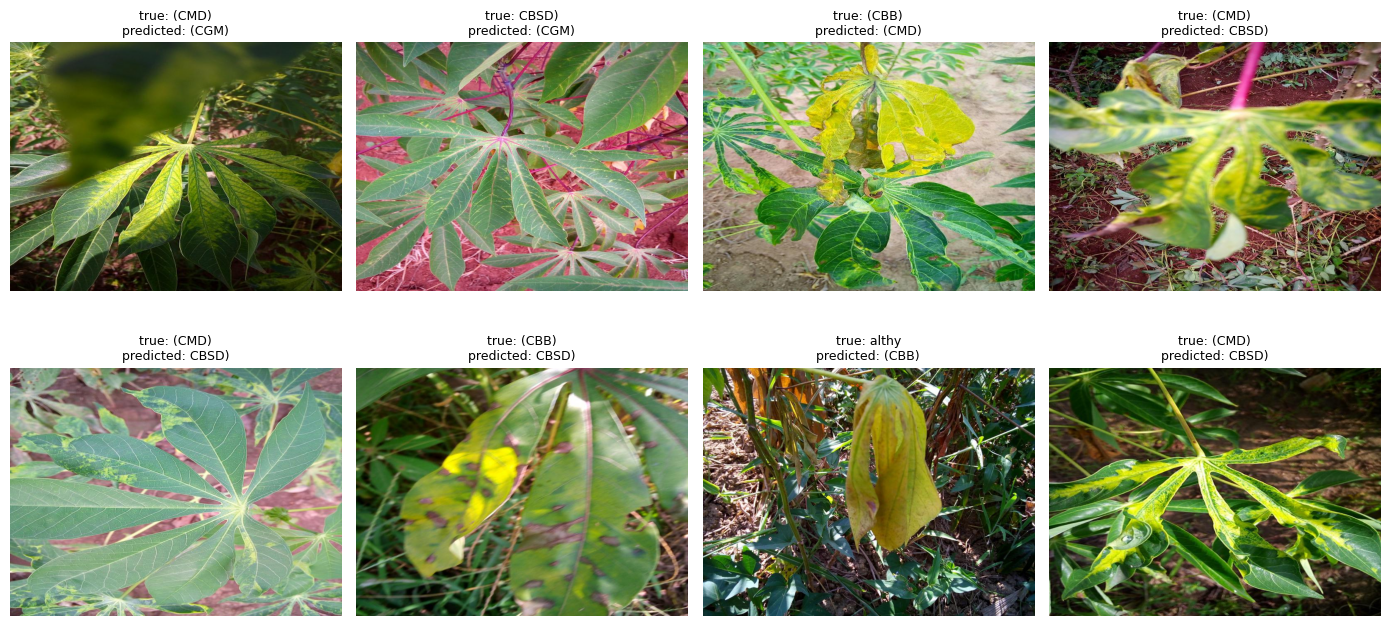

In [11]:
# Error analysis: a few misclassified images
wrong = np.where(y_true != y_pred)[0]
print("Errors:", len(wrong), "out of", len(y_true))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.ravel(), wrong[:8]):
    ax.imshow(plt.imread(test_df["path"].values[idx])); ax.axis("off")
    ax.set_title(f"true: {class_names[y_true[idx]][-5:]}\npredicted: {class_names[y_pred[idx]][-5:]}", fontsize=9)
plt.tight_layout(); plt.show()

In [12]:
model.save("cassava_mobilenetv2.keras")

In [13]:
!ls -lh /kaggle/working

total 21M
-rw-r--r-- 1 root root 21M Nov  8 05:22 cassava_mobilenetv2.keras


In [14]:
 %%writefile /kaggle/working/app.py
"""Prototype: Cassava leaf disease classifier (Gradio).

Upload a photo of a cassava leaf and get the predicted class with confidence scores.
Works in a Kaggle notebook (temporary public link) and on a Hugging Face Space (permanent link).
"""
import os
import numpy as np
import tensorflow as tf
import gradio as gr

# Class order = label numbers 0..4 of the Kaggle dataset
CLASS_NAMES = [
    "Cassava Bacterial Blight (CBB)",
    "Cassava Brown Streak Disease (CBSD)",
    "Cassava Green Mottle (CGM)",
    "Cassava Mosaic Disease (CMD)",
    "Healthy",
]

# Find the saved model (same folder, or the Kaggle working folder)
CANDIDATES = [
    os.environ.get("MODEL_PATH", ""),
    "cassava_mobilenetv2.keras",
    "/kaggle/working/cassava_mobilenetv2.keras",
]
MODEL_PATH = next((p for p in CANDIDATES if p and os.path.exists(p)), None)
if MODEL_PATH is None:
    raise FileNotFoundError("Model file not found. Put cassava_mobilenetv2.keras next to app.py.")

model = tf.keras.models.load_model(MODEL_PATH)
HEIGHT, WIDTH = model.input_shape[1:3]   # read the input size from the model itself


def predict(img):
    if img is None:
        return None
    arr = np.array(img.convert("RGB"), dtype="float32")
    arr = tf.image.resize(arr, (HEIGHT, WIDTH)).numpy()   # same resize as in training
    probs = model.predict(arr[None], verbose=0)[0]        # the model normalises its input itself
    return {CLASS_NAMES[i]: float(probs[i]) for i in range(len(CLASS_NAMES))}


demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Photo of a cassava leaf"),
    outputs=gr.Label(num_top_classes=5, label="Prediction"),
    title="Cassava Leaf Disease Classifier (prototype)",
    description=(
        "Upload a photo of a cassava leaf. The model (MobileNetV2, transfer learning) predicts one of "
        "5 classes: 4 diseases or healthy. Prototype from a student project: about 62% accuracy on the "
        "test set, so always confirm a diagnosis with an agricultural expert."
    ),
)

if __name__ == "__main__":
    # In Kaggle, share=True gives a temporary public link (needs Internet on)
    ON_KAGGLE = os.path.exists("/kaggle")
demo.launch(share=ON_KAGGLE, debug=ON_KAGGLE)

Writing /kaggle/working/app.py


In [15]:
!pip -q install gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [16]:
%run /kaggle/working/app.py

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://3a7dbb988b30c5cd6d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://3a7dbb988b30c5cd6d.gradio.live


<Figure size 640x480 with 0 Axes>

7. Conclusion

**Results.** A MobileNetV2 transfer learning model, trained in two phases (classification head, then fine-tuning of the last 30 layers), reaches 61.3% accuracy and a macro F1 of 0.519 on the 3,210 test images (validation: 62.7% accuracy, macro F1 0.531). Accuracy alone is misleading: CMD is 61.5% of the images, so always answering "CMD" would give about the same accuracy but a macro F1 of only about 0.15. The real gain of the model is on the rare classes.

**Strengths and weaknesses.** CMD is recognised with a high precision (0.94) but a recall of 0.63, so more than a third of CMD leaves are sent to other classes. The four other classes have a recall between 0.48 and 0.70 but a precision between 0.37 and 0.40, because the class weights push the model to predict them often. In particular, 63% of the leaves predicted "Healthy" are actually diseased, which would be the most costly error in practice.

**Variability.** I ran essentially the same configuration three times and got 62.4%, 67.7% and 61.3% accuracy (macro F1 0.526, 0.553 and 0.519). A noisy validation loss and GPU non-determinism explain such differences, so a single run cannot reliably rank two experiments.

**Limitations.** One architecture only, limited tuning, images reduced to 224 x 224 pixels, and a single data source (no test on photos from other regions or phones).

**Next steps (not yet done).** Larger input size (320 to 384 pixels), more layers fine-tuned with a learning rate schedule, softer class weights, EfficientNetB0 as a second architecture, two or three random seeds per configuration, and Grad-CAM to see which parts of the leaf drive the predictions.

## References
- Dataset: Cassava Leaf Disease Classification (Kaggle), Makerere University AI Lab / NaCRRI.
- Libraries: TensorFlow/Keras, scikit-learn, pandas, matplotlib.
- Pre-trained model: MobileNetV2 (ImageNet weights).